# Avance del Reto · Etapas 1 a 4
## Solución de Inteligencia de Negocios para OT Consulting

| | |
|---|---|
| **Alumno** | Alexis Arrazola Jiménez · A01664015 |
| **Materia** | Soporte analítico para la toma de decisiones · Grupo 301 |
| **Socio formador** | OT Consulting (OTC) |
| **Fecha de corte de los datos** | 17 de noviembre de 2026 |
| **Repositorio individual** | [github.com/Arrazola77/OTC-EDA-Individual-Alexis](https://github.com/Arrazola77/OTC-EDA-Individual-Alexis) |

Las etapas se trabajaron en equipo. Este cuaderno, la interpretación y el repositorio son individuales.

### Contenido
1. [Descripción del reto](#1)
2. [Etapas que incluye la presentación](#2)
3. [Requerimientos de análisis: objeto de estudio y preguntas detonadoras](#3)
4. [Métricas e indicadores y su justificación](#4)
5. [Descubrimientos de la exploración de datos](#5)
6. [Tratamiento y acondicionamiento de datos, y reglas de negocio](#6)
7. [Modelo dimensional lógico](#7)
8. [Hallazgos, patrones y recomendaciones para OT Consulting](#8)
9. [Conclusiones y acciones futuras](#9)

> **Cómo correrlo:** pon las tablas acondicionadas de la Etapa 3 (CSV) en `datos/OTC_tablas_acondicionadas_csv/`, o súbelas a `/content` si usas Colab. Los datos de OTC **no se suben al repositorio** porque son información del socio formador. El cuaderno ya está ejecutado y se ve completo en GitHub.

In [1]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_colwidth', 70)
FECHA_CORTE = pd.Timestamp('2026-11-17')

# Paleta usada en todas las gráficas
TINTA, VERDE, AMBAR, ROJO, GRIS = '#16324F', '#1B7F79', '#E9A23B', '#C8553D', '#8A99A6'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'text.parse_math': False})   # el signo $ se muestra como texto

# Busca las tablas acondicionadas (local, Colab o variable de entorno OTC_DATA)
CANDIDATAS = [os.environ.get('OTC_DATA', ''), 'datos/OTC_tablas_acondicionadas_csv',
              '../datos/OTC_tablas_acondicionadas_csv', '/content/OTC_tablas_acondicionadas_csv', '/content']
DATA_DIR = next((d for d in CANDIDATAS if d and os.path.exists(os.path.join(d, 'asignaciones_acondicionada.csv'))), None)
if DATA_DIR is None and os.path.exists('/content'):          # Colab: subir el zip de la Etapa 3
    from google.colab import files
    for nombre in files.upload():
        zipfile.ZipFile(nombre).extractall('/content')
    DATA_DIR = '/content/OTC_tablas_acondicionadas_csv'
assert DATA_DIR, 'No encuentro las tablas acondicionadas (ver la nota de arriba)'

leer = lambda n, fechas=(): pd.read_csv(os.path.join(DATA_DIR, n + '.csv'), parse_dates=list(fechas))
col  = leer('colaboradores_acondicionada', ['fecha_incorporacion', 'fecha_baja'])
asig = leer('asignaciones_acondicionada')
proy = leer('proyectos_acondicionada')
actv = leer('activos_acondicionada')
hab  = leer('habilidades_colaborador')
cob  = leer('habilidades_cobertura')
rol  = leer('roles')
dep  = leer('departamentos')
bit  = leer('bitacora_correcciones')
val  = leer('validaciones')
meta = leer('metadata_tablas')

inventario = pd.DataFrame([
    ('colaboradores_acondicionada', col,  'Una fila por colaborador (activos y bajas)', 'id_colaborador'),
    ('asignaciones_acondicionada',  asig, 'Una fila por asignación persona-proyecto',    'id_asignacion'),
    ('proyectos_acondicionada',     proy, 'Una fila por proyecto de cliente',             'id_proyecto'),
    ('activos_acondicionada',       actv, 'Una fila por equipo de cómputo',               'cod_activo'),
    ('habilidades_colaborador',     hab,  'Una fila por persona y habilidad evaluada',    'id_colaborador + codigo_habilidad'),
    ('habilidades_cobertura',       cob,  'Una fila por habilidad',                       'codigo_habilidad'),
    ('roles',                       rol,  'Una fila por rol',                             'codigo_rol'),
    ('departamentos',               dep,  'Una fila por departamento',                    'codigo_departamento'),
], columns=['tabla', 'df', 'granularidad', 'llave'])
inventario['filas'] = inventario.df.map(len)
inventario['columnas'] = inventario.df.map(lambda d: d.shape[1])
print(f"8 tablas acondicionadas · {inventario.columnas.sum()} columnas documentadas en la metadata ({len(meta)} filas)")
inventario.drop(columns='df')[['tabla', 'filas', 'columnas', 'granularidad', 'llave']]

8 tablas acondicionadas · 176 columnas documentadas en la metadata (176 filas)


,tabla,filas,columnas,granularidad,llave
0,colaboradores_acondicionada,107,68,Una fila por colaborador (activos y bajas),id_colaborador
1,asignaciones_acondicionada,31,34,Una fila por asignación persona-proyecto,id_asignacion
2,proyectos_acondicionada,12,22,Una fila por proyecto de cliente,id_proyecto
3,activos_acondicionada,123,22,Una fila por equipo de cómputo,cod_activo
4,habilidades_colaborador,1529,9,Una fila por persona y habilidad evaluada,id_colaborador + codigo_habilidad
5,habilidades_cobertura,71,11,Una fila por habilidad,codigo_habilidad
6,roles,54,6,Una fila por rol,codigo_rol
7,departamentos,6,4,Una fila por departamento,codigo_departamento


<a id="1"></a>
## 1. Descripción del reto

**OT Consulting** es una consultora de TI de Monterrey. Es Oracle Gold Partner, trabaja ERP y transformación digital, y gana dinero **colocando consultores en proyectos de sus clientes** (Metalsa, Grupo Daltile, Allegion, Citi, entre otros).

**Problema de negocio.** OTC no tiene un control confiable de la asignación de su gente. No sabe con certeza quién está en qué proyecto, desde cuándo y hasta cuándo, con qué rol, ni cuánto le cuesta cada asignación. Sin eso no puede medir su **banca** (personal pagado sin proyecto), anticipar reasignaciones ni costear sus proyectos.

**Objetivo del reto.** Diseñar y construir una solución de Inteligencia de Negocios que:
- integre las 10 fuentes de OTC (archivos de Excel de su ERP de personal, nómina, clientes, activos y habilidades) en una base única y depurada,
- la modele para el análisis, con un modelo dimensional de Kimball,
- y la convierta en indicadores y tableros para decidir sobre capacidad, costo y talento.

**Enfoque metodológico.** Como científicos de datos seguimos **CRISP-DM** para el ciclo del proyecto y **Kimball** para el diseño del almacén. Las 4 etapas cubren las primeras fases de CRISP-DM: entendimiento del negocio, entendimiento de los datos, preparación y modelado.

**Alcance y limitación.** Las fuentes no traen tarifas ni ingresos. Por eso el estudio mide **costo, capacidad y talento**, no rentabilidad.

<a id="2"></a>
## 2. Etapas que incluye la presentación

| Etapa | Fecha | Fase CRISP-DM | Qué hicimos | Evidencia en este repositorio |
|---|---|---|---|---|
| **1. Justificación y planeación** | 13-nov | Entendimiento del negocio | Objetivo, justificación, descripción de OTC, hipótesis de necesidades y guía de entrevista con el socio formador | Resumen en esta sección |
| **2. Análisis y exploración de datos** | 17-nov | Entendimiento de los datos | Perfilado de las 10 fuentes, bitácora de 60 hallazgos de calidad, reglas de negocio, preguntas detonadoras, métricas e indicadores | [`README.md`](README.md), [`OTC_EDA.ipynb`](OTC_EDA.ipynb) y [`Agregar_columnas/`](Agregar_columnas) |
| **3. Tratamiento y acondicionamiento** | 20-nov | Preparación de los datos | ETL en Python: 11 métodos de corrección, 37 correcciones, 25 validaciones, 8 tablas limpias y su metadata | [`OTC_Etapa3_Acondicionamiento.ipynb`](OTC_Etapa3_Acondicionamiento.ipynb) y [`Etapa3_Acondicionamiento.md`](Etapa3_Acondicionamiento.md) |
| **4. Diseño del modelo dimensional lógico** | 23-nov | Modelado | Modelo en estrella con `HECHOS_ASIGNACION` y 6 dimensiones | [`Etapa4_Modelo_Dimensional.md`](Etapa4_Modelo_Dimensional.md) y sección 7 |

**Lo que aprendimos de la Etapa 1 a la 2.** La Etapa 1 se escribió antes de tener los datos, así que planteó hipótesis comerciales: ciclo de venta, CRM e ingresos SaaS. Cuando recibimos las 10 fuentes vimos que la información real de OTC es de **capital humano y operación**: plantilla, nómina, asignaciones, habilidades y equipos. Por eso el alcance se redefinió alrededor de la **asignación de consultores a proyectos**. Esa decisión guía todo lo que sigue.

<a id="3"></a>
## 3. Requerimientos de análisis

### 3.1 Objeto de estudio
> **La asignación de un colaborador a un proyecto durante un periodo.**

Es el hecho de negocio que OTC necesita controlar. Se mide por su **costo mensual** (Sueldo Total Integrado repartido por dedicación), su **vigencia** (fechas efectivas, días para el fin) y el **perfil** de la persona (rol y habilidades). Alrededor de este hecho analizamos la capacidad libre (banca), la rotación, el talento y los equipos.

### 3.2 Preguntas detonadoras
La numeración es la final, la que usamos desde la Etapa 3. El README de la Etapa 2 tenía otro orden.

| Tema | ID | Pregunta | Atributos que la responden |
|---|---|---|---|
| Asignación y capacidad | **P1** | ¿Cuántos colaboradores activos están asignados y cuántos están en banca? | `tiene_asignacion`, `en_banca`, `en_banca_ajustada` |
| | **P2** | ¿Qué asignaciones terminan en los próximos 30, 60 y 90 días y quién queda libre? | `dias_para_fin`, `estado_vigencia`, `persona_libre_al_vencer` |
| | **P3** | ¿Qué proyectos en curso no tienen personal o PM? | `n_personas_asignadas`, `sin_personal`, `pm_sin_asignar` |
| Costo | **P4** | ¿Cuál es el costo por hora de cada colaborador? | `costo_mensual`, `costo_hora` |
| | **P5** | ¿Cuánto cuesta al mes cada proyecto y cada cliente? | `pct_dedicacion`, `costo_mensual_asignado`, `costo_mensual_proyecto` |
| | **P6** | ¿Cuánto le cuesta a OTC su banca y de qué tipo es? | `costo_mensual_banca`, `tipo_banca` |
| Talento, personas y activos | **P7** | ¿Qué habilidades tienen menos de 2 personas activas en nivel Avanzado o Experto? | `n_nivel3plus_activos`, `cobertura_baja` |
| | **P8** | ¿Qué personas en banca podrían cubrir los proyectos sin personal? | `n_habs_nivel3plus`, `matriz_confiable`, `top_habilidades` |
| | **P9** | ¿Cuál es la rotación mensual y en qué puestos se concentra? | `anio_mes_baja`, `baja_sin_fecha`, `nivel_puesto` |
| | **P10** | ¿Cuántos expedientes de personal están completos? | `docs_basicos_ok`, `expediente_completo` |
| | **P11** | ¿Cuántos equipos siguen a nombre de personas dadas de baja y cuánto valen? | `situacion_equipo`, `equipo_por_recuperar`, `valor_por_recuperar` |

<a id="4"></a>
## 4. Métricas e indicadores

Distinguimos dos conceptos:
- Una **métrica** es una medida numérica del hecho, por ejemplo el costo mensual de una asignación.
- Un **indicador** compara una métrica contra una **meta** para decir si el negocio va bien o mal.

### 4.1 Métricas de la tabla de hechos
La **aditividad** de cada métrica define cómo la puede agregar la herramienta de BI. Si no se respeta, el tablero suma cosas que no se pueden sumar.

| Métrica | Unidad | Cálculo | Aditividad | Por qué existe |
|---|---|---|---|---|
| `costo_mensual_asignado` | MXN | $C_{i,j} = C_i \cdot \delta_{i,j}$ | **Aditiva** | Es la única forma de costear proyectos y clientes: $C_j=\sum_i C_{i,j}$ (P5) |
| `pct_dedicacion` | 0–1 | $\delta_{i,j} = 1/n_i$ (R06) | **Semiaditiva**: se suma por persona, con un máximo de 1 | Controla la sobreasignación (R04) |
| `duracion_dias` | días | fin efectivo − inicio efectivo | Aditiva, aunque tiene más sentido promediarla | Mide la duración típica de una asignación |
| `dias_para_fin` | días | fin efectivo − fecha de corte | **No aditiva**: depende de la fecha de corte | Alerta de vencimiento (P2) |
| `n_asignaciones_persona` | conteo | asignaciones en curso de la persona | No aditiva: se repite en cada fila de la persona | Denominador del reparto de costo |
| `costo_mensual_persona` | MXN | Sueldo Total Integrado (R03) | No aditiva: se repite | Costo completo de la persona |
| `costo_hora_persona` | MXN/h | $C_i / 160$ (R10) | No aditiva: se promedia | Costo por hora para cotizar (P4) |

### 4.2 Indicadores y su justificación

| Indicador | Fórmula | Meta sugerida | Pregunta | Razón de ser |
|---|---|---|---|---|
| **Tasa de utilización** | activos con asignación / activos | ≥ 85 % | P1 | En consultoría, la capacidad que no está asignada no genera ingreso |
| **Peso de la banca** | costo de la banca / nómina activa | ≤ 10 % | P6 | Traduce la capacidad ociosa a pesos, que es el lenguaje de la dirección |
| **Proyectos sin cobertura** | proyectos en curso sin personal / proyectos en curso | 0 % | P3 | Un proyecto sin gente es un riesgo de incumplir con el cliente |
| **Asignaciones por vencer** | asignaciones que terminan en 30, 60 y 90 días | 100 % con plan de reasignación | P2 | Permite reasignar a la persona antes de que caiga en banca |
| **Cobertura de habilidad** | activos en nivel Avanzado o superior por habilidad | ≥ 2 por habilidad | P7 | Con menos de 2 personas, OTC depende de una sola persona |
| **Rotación mensual** | bajas del mes / plantilla al inicio del mes | < 2 % | P9 | Mide la pérdida de talento y de conocimiento del cliente |
| **Expedientes completos** | activos con 7 de 7 documentos / activos | 100 % | P10 | Cumplimiento laboral y riesgo legal |
| **Equipos por recuperar** | equipos a nombre de bajas sin devolver | 0 | P11 | Control patrimonial |
| **Calidad de datos** | validaciones aprobadas / validaciones | 100 % | Todas | Sin datos confiables, ningún indicador sirve |

Las metas son sugeridas y se tienen que validar con el usuario principal de OTC. La siguiente celda calcula cada indicador directamente de las tablas acondicionadas.

In [2]:
act = col[col.es_activo]
n_act = len(act)
nomina = act.costo_mensual.sum()
banca = act.loc[act.en_banca, 'costo_mensual_banca'].sum()
en_curso = proy[proy.estatus_proyecto == 'EN CURSO']
vig = asig.estado_vigencia.value_counts()

# Rotación de octubre: bajas del mes / personas en OTC el 1-oct (sin contar bajas sin fecha)
ini = pd.Timestamp('2026-10-01')
hc_oct = ((col.fecha_incorporacion < ini) & (col.fecha_baja.isna() | (col.fecha_baja >= ini))
          & ~(col.estatus_corte.eq('BAJA') & col.fecha_baja.isna())).sum()
bajas_oct = (col.anio_mes_baja == '2026-10').sum()

ind = pd.DataFrame([
    ('Tasa de utilización',      act.tiene_asignacion.mean() * 100, 85, '≥', '%', f'{act.tiene_asignacion.sum()} de {n_act} activos'),
    ('Peso de la banca',         banca / nomina * 100,              10, '≤', '%', f'${banca:,.0f} de ${nomina:,.0f} al mes'),
    ('Proyectos sin cobertura',  en_curso.sin_personal.mean() * 100, 0, '≤', '%', f'{en_curso.sin_personal.sum()} de {len(en_curso)} en curso'),
    ('Asignaciones vencidas',    vig.get('VENCIDA', 0),              0, '≤', '',  f"por vencer 30/60/90 d: {vig.get('0-30 DÍAS',0)}/{vig.get('31-60 DÍAS',0)}/{vig.get('61-90 DÍAS',0)}"),
    ('Habilidades con cobertura baja', cob.cobertura_baja.sum(),     0, '≤', '',  f'de {len(cob)} habilidades; {(cob.n_nivel3plus_activos == 0).sum()} con nadie'),
    ('Rotación de octubre',      bajas_oct / hc_oct * 100,           2, '<', '%', f'{bajas_oct} bajas / {hc_oct} personas al 1-oct'),
    ('Expedientes completos',    act.expediente_completo.mean() * 100, 100, '≥', '%', f'{act.expediente_completo.sum()} de {n_act}'),
    ('Equipos por recuperar',    actv.equipo_por_recuperar.sum(),    0, '≤', '',  f'valor conocido ${actv.valor_por_recuperar.sum():,.0f}'),
    ('Validaciones aprobadas',   (val.resultado == 'OK').mean() * 100, 100, '≥', '%', f"{(val.resultado == 'OK').sum()} de {len(val)}"),
], columns=['indicador', 'valor', 'meta', 'sentido', 'unidad', 'detalle'])

def cumple(r):
    return {'≥': r.valor >= r.meta, '≤': r.valor <= r.meta, '<': r.valor < r.meta}[r.sentido]
ind['estado'] = np.where(ind.apply(cumple, axis=1), 'Cumple', 'Fuera de meta')
fmt = lambda r: f"{r.valor:.1f}{r.unidad}" if r.unidad else f"{r.valor:.0f}"
tabla_ind = ind.assign(valor_al_corte=ind.apply(fmt, axis=1),
                       meta_=ind.sentido + ' ' + ind.meta.astype(str) + ind.unidad)
tabla_ind[['indicador', 'valor_al_corte', 'meta_', 'estado', 'detalle']].rename(columns={'meta_': 'meta'})

,indicador,valor_al_corte,meta,estado,detalle
0,Tasa de utilización,40.0%,≥ 85%,Fuera de meta,30 de 75 activos
1,Peso de la banca,50.9%,≤ 10%,Fuera de meta,"$1,994,154 de $3,918,864 al mes"
2,Proyectos sin cobertura,57.1%,≤ 0%,Fuera de meta,4 de 7 en curso
3,Asignaciones vencidas,3,≤ 0,Fuera de meta,por vencer 30/60/90 d: 0/0/0
4,Habilidades con cobertura baja,11,≤ 0,Fuera de meta,de 71 habilidades; 6 con nadie
5,Rotación de octubre,14.6%,< 2%,Fuera de meta,12 bajas / 82 personas al 1-oct
6,Expedientes completos,54.7%,≥ 100%,Fuera de meta,41 de 75
7,Equipos por recuperar,9,≤ 0,Fuera de meta,"valor conocido $40,693"
8,Validaciones aprobadas,96.0%,≥ 100%,Fuera de meta,24 de 25


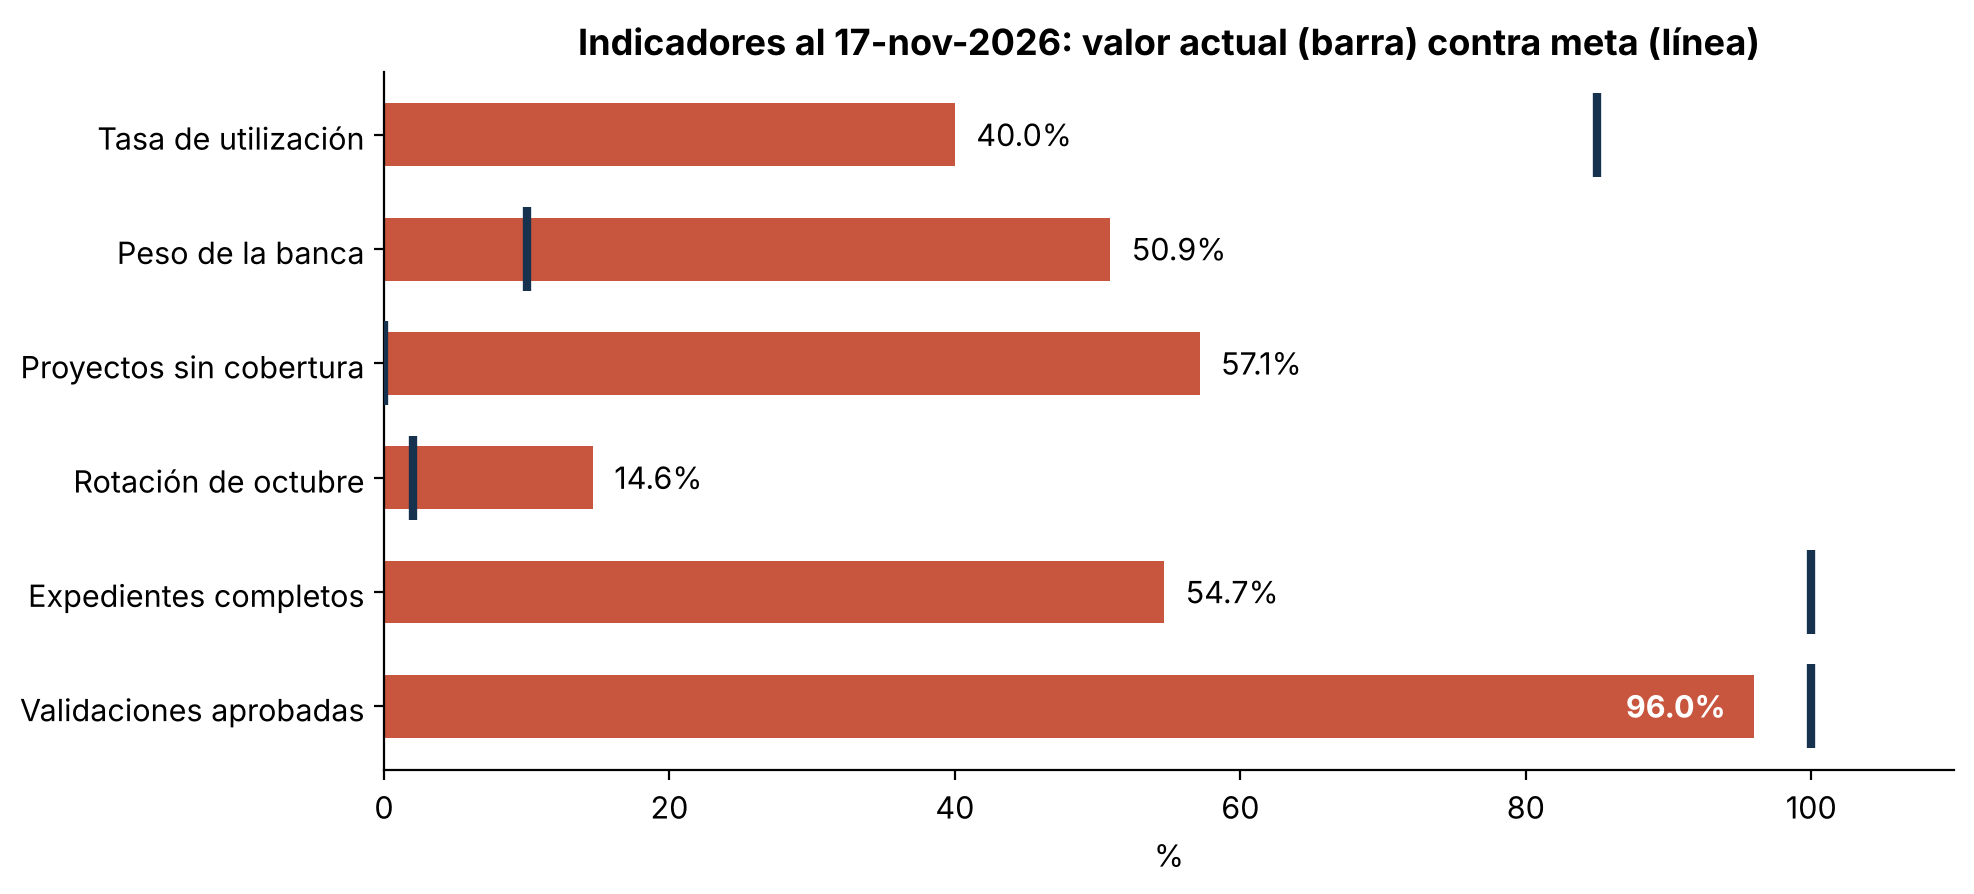

In [3]:
# Indicadores en porcentaje: valor al 17-nov contra su meta
pct = ind[ind.unidad == '%'].iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(pct))
colores = [VERDE if e == 'Cumple' else ROJO for e in pct.estado]
ax.barh(y, pct.valor, color=colores, height=0.55)
ax.scatter(pct.meta, y, marker='|', s=900, color=TINTA, linewidths=3, zorder=3)
for yi, v in zip(y, pct.valor):
    if v > 80:   # etiqueta dentro de la barra para no chocar con la línea de meta
        ax.text(v - 2, yi, f'{v:.1f}%', va='center', ha='right', fontsize=11, color='white', fontweight='bold')
    else:
        ax.text(v + 1.5, yi, f'{v:.1f}%', va='center', fontsize=11)
ax.set_yticks(y, pct.indicador)
ax.set_xlim(0, 110); ax.set_xlabel('%')
ax.set_title('Indicadores al 17-nov-2026: valor actual (barra) contra meta (línea)')

plt.tight_layout(); plt.show()

<a id="5"></a>
## 5. Descubrimientos de la exploración de datos (Etapa 2)

Perfilamos las 10 fuentes columna por columna: tipo, nulos, únicos, duplicados y cuadre de fórmulas. Registramos **60 hallazgos de calidad, 21 de severidad alta**. Estos son los más importantes:

1. **La asignación, que es el hecho central, casi no tiene datos.** Solo 30 de 75 activos aparecen en Asignaciones. Además, 29 de 31 asignaciones tienen el rol en "PENDIENTE" y 21 empiezan el 01/01/1990, que es una fecha de relleno.
2. **Las fechas no coinciden entre tablas.** Marazzi termina el 23-sep-2026 en el catálogo de Clientes, pero en Asignaciones sigue "En Curso" hasta el 01-ene-2027. Hay proyectos "En Curso" ya vencidos.
3. **La nómina sí es confiable.** El Sueldo Total Integrado cuadra con sus componentes en las 107 filas (neto IMSS + asimilados + complementos + comisión + impuestos), así que se puede usar como costo.
4. **Hay inconsistencias de estatus.** Encontramos 12 bajas con sueldo mayor a 0, 5 activos con sueldo 0 y 18 bajas sin fecha.
5. **El catálogo de personas está incompleto.** El puesto está en "PENDIENTE" en 29 de 75 activos y el departamento viene vacío en casi todos los registros.
6. **Los activos se ligaban por nombre y no por ID.** Hay equipos a nombre de personas dadas de baja, y 70 de 123 equipos tienen costo 0.
7. **Hay tablas duplicadas.** Sueldos_Salarios e Inversion_Activos repiten el catálogo fila por fila.

La Etapa 3 no borró estos hallazgos. Cada uno quedó como **bandera** en las tablas limpias, como muestra la siguiente celda.

In [4]:
hallazgos = pd.DataFrame([
    ('Asignaciones', 'Rol asignado desconocido (era PENDIENTE)',    asig.rol_asignado.isna().sum(), len(asig)),
    ('Asignaciones', 'Inicio desconocido (era 01/01/1990)',          asig.fecha_inicio_desconocida.sum(), len(asig)),
    ('Asignaciones', 'Fin indefinido (texto "Indefinido")',          asig.fin_indefinido.sum(), len(asig)),
    ('Asignaciones', 'Fechas ajustadas al proyecto (R08)',           asig.ajustada_r08.sum(), len(asig)),
    ('Colaboradores','Activos sin asignación registrada',            act.en_banca.sum(), n_act),
    ('Colaboradores','Activos sin puesto (tras recuperar 2 por cruce)', act.puesto_faltante.sum(), n_act),
    ('Colaboradores','Activos con sueldo faltante (sueldo 0)',       act.sueldo_faltante.sum(), n_act),
    ('Colaboradores','Bajas sin fecha de baja',                      col.baja_sin_fecha.sum(), (col.estatus_corte == 'BAJA').sum()),
    ('Proyectos',    'Proyectos sin PM de OTC',                      proy.pm_sin_asignar.sum(), len(proy)),
    ('Activos',      'Equipos con costo desconocido (era 0)',        actv.costo_desconocido.sum(), len(actv)),
], columns=['tabla', 'hallazgo', 'registros', 'universo'])
hallazgos['%'] = (hallazgos.registros / hallazgos.universo * 100).round(1)
hallazgos

,tabla,hallazgo,registros,universo,%
0,Asignaciones,Rol asignado desconocido (era PENDIENTE),29,31,93.5
1,Asignaciones,Inicio desconocido (era 01/01/1990),21,31,67.7
2,Asignaciones,"Fin indefinido (texto ""Indefinido"")",24,31,77.4
3,Asignaciones,Fechas ajustadas al proyecto (R08),3,31,9.7
4,Colaboradores,Activos sin asignación registrada,45,75,60.0
5,Colaboradores,Activos sin puesto (tras recuperar 2 por cruce),27,75,36.0
6,Colaboradores,Activos con sueldo faltante (sueldo 0),5,75,6.7
7,Colaboradores,Bajas sin fecha de baja,18,32,56.2
8,Proyectos,Proyectos sin PM de OTC,6,12,50.0
9,Activos,Equipos con costo desconocido (era 0),70,123,56.9


<a id="6"></a>
## 6. Tratamiento y acondicionamiento de datos (Etapa 3)

### 6.1 Mecanismo
El tratamiento es un **proceso ETL reproducible en Python (pandas)**, en el cuaderno [`OTC_Etapa3_Acondicionamiento.ipynb`](OTC_Etapa3_Acondicionamiento.ipynb). Corre de principio a fin sin pasos manuales:

**Extracción** de los 10 Excel → **limpieza** (M01–M03) → **recuperación por cruce** de fuentes (M04) → **reglas de fechas y estatus** (M05, M06) → **reparto del costo** (M07) → **integración por llave** (M08, M09) → **minimización de datos personales** (M10) → **banderas** (M11) → **25 validaciones** → **exportación** de 8 tablas y metadata.

**Principio de trabajo: nunca se inventa un dato.** No imputamos con promedios ni con la moda. Lo que no se pudo recuperar de otra fuente queda en **nulo con una bandera** que explica por qué. Así el tablero puede mostrar la *falta de captura* como un problema de proceso de OTC y no la esconde.

| Método | Qué hace | Reglas |
|---|---|---|
| M01 Normalización de texto | Quita espacios sobrantes y pasa el texto a mayúsculas | R11 |
| M02 Marcadores a nulo con bandera | PENDIENTE, 1990-01-01, "Indefinido", sueldo 0 y costo 0 pasan a nulo | R03, R07, R11 |
| M03 Catálogos de equivalencias | Junta valores que significan lo mismo: 9 claves de nómina quedan en 7 esquemas y 12 marcas en 5 | R11 |
| M04 Recuperación por cruce | Completa puesto, departamento y rol con otra fuente, uniendo por ID | R01 |
| M05 Fechas según el proyecto | Recorta la asignación a las fechas del proyecto y conserva la fecha original | R08 |
| M06 Estatus y costo al corte | Calcula el estatus al 17-nov, pone costo 0 a las bajas y usa solo activos en la cobertura | R02, R03 |
| M07 Reparto del costo | Divide el costo entre las asignaciones en partes iguales ($1/n_i$) | R04, R06 |
| M08 Integración por llave | Crea `id_proyecto` y liga los equipos por ID, no por nombre | R01, R09 |
| M09 Conciliación de duplicados | Compara las tablas repetidas y deja de usar las redundantes | R01 |
| M10 Minimización de datos | Quita RFC, CURP, NSS, contacto, domicilio y otros datos personales sin uso | R12 |
| M11 Banderas en lugar de imputar | Deja lo no recuperable en nulo y lo señala con una bandera | R02, R08, R09 |

In [5]:
# Evidencia: bitácora de correcciones y validaciones automáticas
bit['estado'] = np.where(bit.pendientes_despues == 0, 'Resuelta', 'Marcada con bandera')
resumen = (bit.groupby('metodo')
              .agg(correcciones=('id', 'size'), registros_antes=('afectados_antes', 'sum'),
                   pendientes_despues=('pendientes_despues', 'sum'))
              .reset_index())
print(f"Bitácora: {len(bit)} correcciones · {(bit.estado == 'Resuelta').sum()} resueltas · "
      f"{(bit.estado != 'Resuelta').sum()} marcadas con bandera (no se puede recuperar sin OTC)")
print(f"Validaciones: {(val.resultado == 'OK').sum()} de {len(val)} aprobadas")
display(val[val.resultado != 'OK'][['id', 'validacion', 'resultado', 'detalle']])
resumen

Bitácora: 37 correcciones · 20 resueltas · 17 marcadas con bandera (no se puede recuperar sin OTC)
Validaciones: 24 de 25 aprobadas


,id,validacion,resultado,detalle
5,V06,Cada PM de OTC existe como colaborador (R05),FALLA,6 PM no se encuentran por nombre en el catálogo (R05 no se cumple;...


,metodo,correcciones,registros_antes,pendientes_despues
0,M01,4,666,0
1,M02,7,297,214
2,M03,5,59,39
3,M04,4,140,89
4,M05,2,4,0
5,M06,3,52,0
6,M07,1,2,0
7,M08,1,32,0
8,M09,2,198,0
9,M10,3,18,0


Costo asignado a proyectos  $   1,924,711
Costo de la banca           $   1,994,154
Suma                        $   3,918,864
Nómina activa               $   3,918,864   ->  cuadra: True


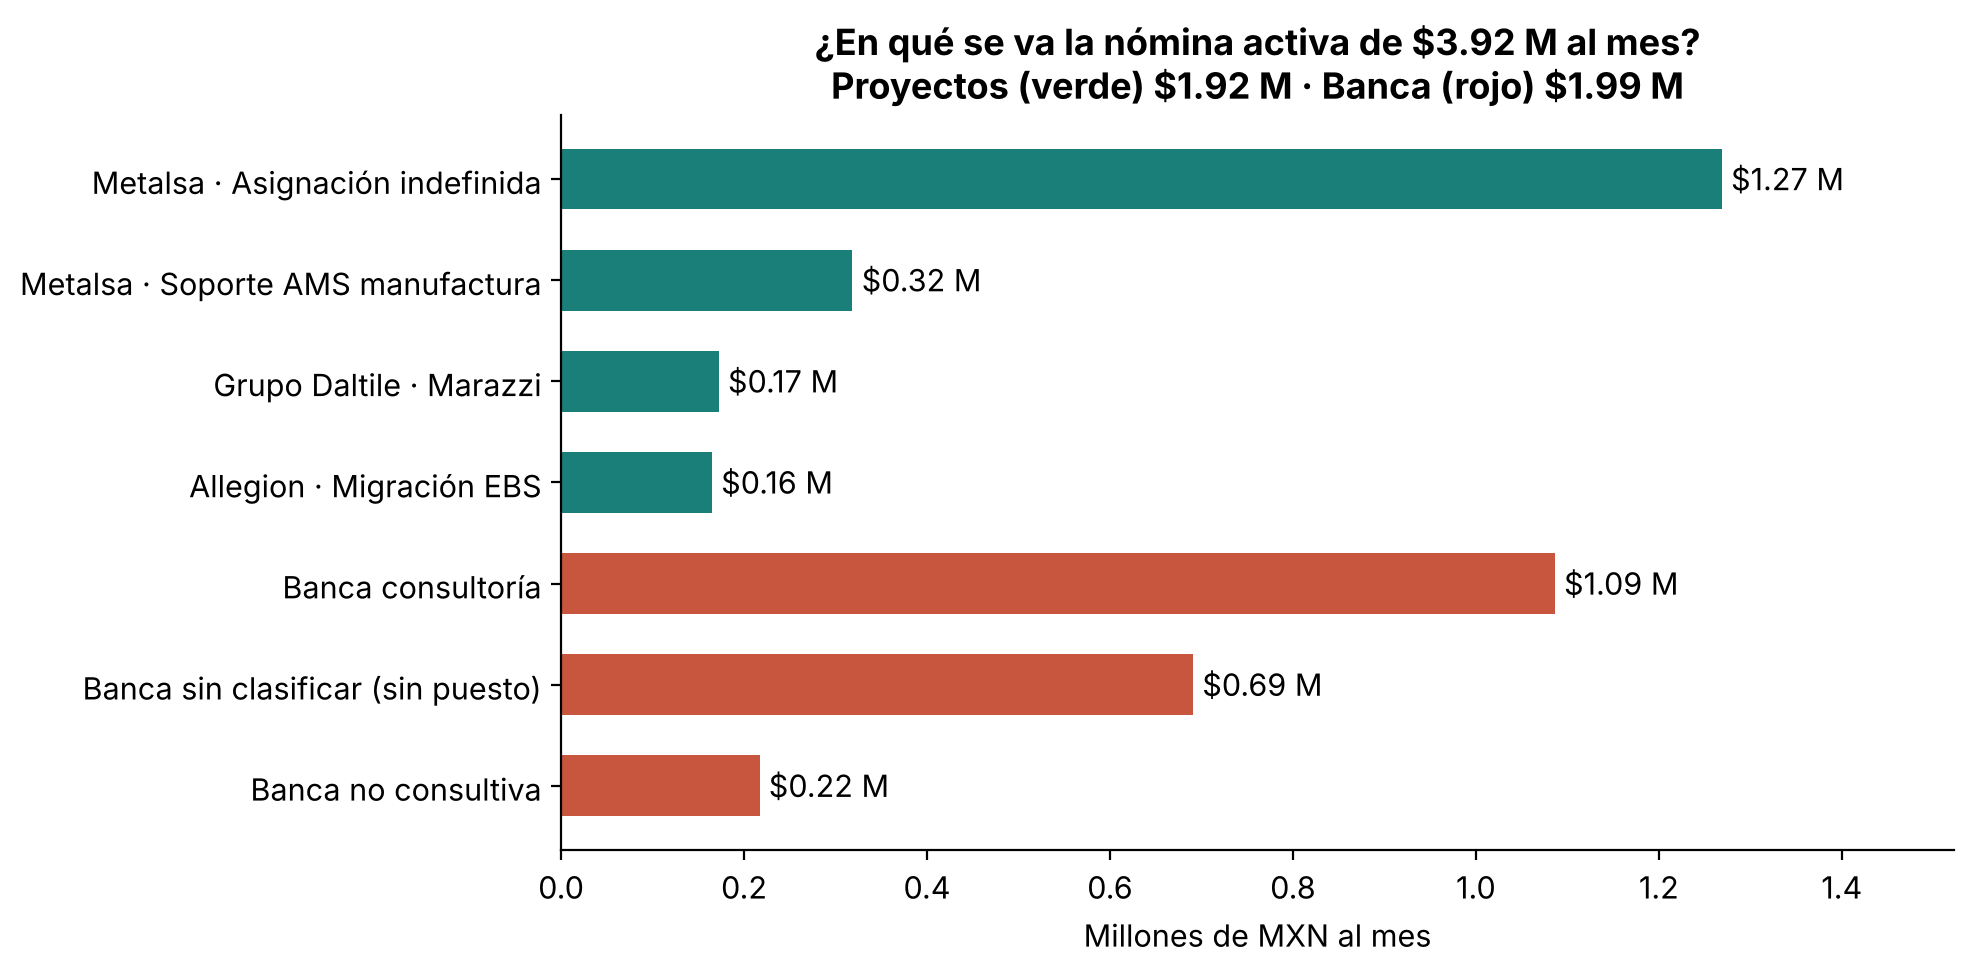

In [6]:
# Conservación del costo (validación V17): todo peso de la nómina activa está en un proyecto o en la banca
asignado = asig.costo_mensual_asignado.sum()
print(f"Costo asignado a proyectos  ${asignado:>12,.0f}")
print(f"Costo de la banca           ${banca:>12,.0f}")
print(f"Suma                        ${asignado + banca:>12,.0f}")
print(f"Nómina activa               ${nomina:>12,.0f}   ->  cuadra: {abs(asignado + banca - nomina) < 1}")

por_proy = asig.groupby(['cliente', 'proyecto']).costo_mensual_asignado.sum().sort_values()
por_proy.index = [f"{c.title()} · {p.capitalize().replace('ams', 'AMS').replace('ebs', 'EBS')}" for c, p in por_proy.index]
por_banca = act[act.en_banca].groupby('tipo_banca').costo_mensual_banca.sum().sort_values()
por_banca.index = [t.capitalize() for t in por_banca.index]

fig, ax = plt.subplots(figsize=(10, 5))
etq = list(por_banca.index) + list(por_proy.index)
vals = list(por_banca.values) + list(por_proy.values)
cols = [ROJO] * len(por_banca) + [VERDE] * len(por_proy)
ax.barh(etq, np.array(vals) / 1e6, color=cols, height=0.6)
for i, v in enumerate(vals):
    ax.text(v / 1e6 + 0.01, i, f'${v/1e6:.2f} M', va='center')
ax.set_xlabel('Millones de MXN al mes')
ax.set_title(f'¿En qué se va la nómina activa de ${nomina/1e6:.2f} M al mes?\n'
             f'Proyectos (verde) ${asignado/1e6:.2f} M · Banca (rojo) ${banca/1e6:.2f} M')
ax.set_xlim(0, max(vals) / 1e6 * 1.2)
plt.tight_layout(); plt.show()

In [7]:
# Ejemplo de cómo el tratamiento cambió una conclusión: R08 en las asignaciones de Marazzi
cols_vis = ['id_asignacion', 'id_colaborador', 'proyecto', 'fecha_fin_registrada', 'fecha_fin_efectiva',
            'fuente_fecha_fin', 'ajustada_r08', 'dias_para_fin', 'estado_vigencia']
asig.loc[asig.ajustada_r08, cols_vis]

,id_asignacion,id_colaborador,proyecto,fecha_fin_registrada,fecha_fin_efectiva,fuente_fecha_fin,ajustada_r08,dias_para_fin,estado_vigencia
4,A005,OTC014,MARAZZI,2027-01-01,2026-09-23,PROYECTO (ajustada R08),True,-55.0,VENCIDA
9,A010,OTC050,MARAZZI,2027-01-01,2026-09-23,PROYECTO (ajustada R08),True,-55.0,VENCIDA
22,A023,OTC095,MARAZZI,2027-01-01,2026-09-23,PROYECTO (ajustada R08),True,-55.0,VENCIDA


En la Etapa 2, las 3 asignaciones de Marazzi aparecían **"por vencer en 31–60 días"** porque Asignaciones decía que terminaban el 01-ene-2027. Con la regla **R08**, la fuente oficial de fechas es el catálogo de Clientes, y ahí el proyecto terminó el 23-sep-2026. Por eso ahora aparecen como **vencidas**: hay 3 personas que podrían estar en banca sin que OTC lo sepa. El acondicionamiento no es solo limpieza, porque **cambia la respuesta de negocio**.

### 6.2 Reglas de negocio
Sí hizo falta definir reglas de negocio. Sin ellas, los datos no se podían interpretar: por ejemplo, saber si un sueldo 0 es un costo cero o un dato faltante. Las definimos en la Etapa 2 y las aplicamos en la Etapa 3:

| Regla | Definición | Se aplica con |
|---|---|---|
| R01 | La llave de un colaborador es su ID; nunca se une por nombre | M04, M08, M09 |
| R02 | Un colaborador está activo si su estatus es Activo y no tiene baja antes del corte | M06, M11 |
| R03 | El costo mensual es el Sueldo Total Integrado; un sueldo 0 en un activo es dato faltante | M02, M06 |
| R04 | La dedicación total de una persona no puede pasar de 100 % | M07 y validación V10 |
| R05 | Todo PM de OTC debe existir en el catálogo de colaboradores | Validación V06 (**no se cumple**) |
| R06 | Sin % de dedicación, el costo se reparte en partes iguales | M07 |
| R07 | 01/01/1990, "Indefinido", "Activo" (en una fecha) y PENDIENTE equivalen a nulo con bandera | M02 |
| R08 | Las fechas de la asignación deben caber en las del proyecto; Clientes es la fuente oficial | M05, M11 |
| R09 | Un equipo tiene un solo responsable, ligado por ID | M08, M11 |
| R10 | Un mes laboral son 160 horas; costo por hora = Sueldo Total Integrado / 160 | Atributo `costo_hora` |
| R11 | El texto va sin espacios sobrantes, en mayúsculas y con catálogos de equivalencias | M01, M03 |
| R12 | Los datos personales sin uso analítico se eliminan | M10 |

<a id="7"></a>
## 7. Modelo dimensional lógico (Etapa 4)

Aplicamos los 4 pasos de diseño de **Kimball**:

1. **Proceso de negocio:** asignación de colaboradores a proyectos.
2. **Granularidad:** una fila por asignación de un colaborador a un proyecto (`id_asignacion`). Si una persona está en dos proyectos, tiene dos filas. Es el grano más fino disponible, así que permite agregar hacia arriba (por proyecto, cliente, rol o mes) sin perder detalle.
3. **Dimensiones:** quién (Colaborador), para quién y en qué (Proyecto, con la jerarquía Cliente > Proyecto), con qué función (Rol), cuándo (Fecha) y en qué situación (Estado de la asignación y Calidad de la fecha).
4. **Hechos:** las 7 métricas de la sección 4.1.

**Decisiones de diseño:**
- **Esquema en estrella, no copo de nieve.** Cliente y Proyecto quedan desnormalizados en una sola dimensión para que las consultas usen menos uniones y la herramienta de BI responda más rápido.
- **Dimensión degenerada.** `id_asignacion` se queda en la tabla de hechos porque no tiene atributos propios.
- **Dimensión de rol múltiple (*role-playing*).** `DIM_FECHA` se conecta 4 veces: inicio efectivo, fin efectivo, inicio registrado y fin registrado. Así se pueden comparar la fecha original contra la corregida.
- **Dimensiones de banderas (*junk dimensions*).** `DIM_ESTADO_ASIGNACION` y `DIM_CALIDAD_FECHA` agrupan las banderas de baja cardinalidad en una sola llave cada una, en lugar de 9 columnas sueltas en la tabla de hechos.
- **Miembro "desconocido" en `DIM_FECHA`.** Las fechas que no existen en el origen apuntan a ese miembro en lugar de quedar como llaves huérfanas.
- **Llaves sustitutas (FK\*)** para Rol, Estado y Calidad, que no traían llave en el origen.

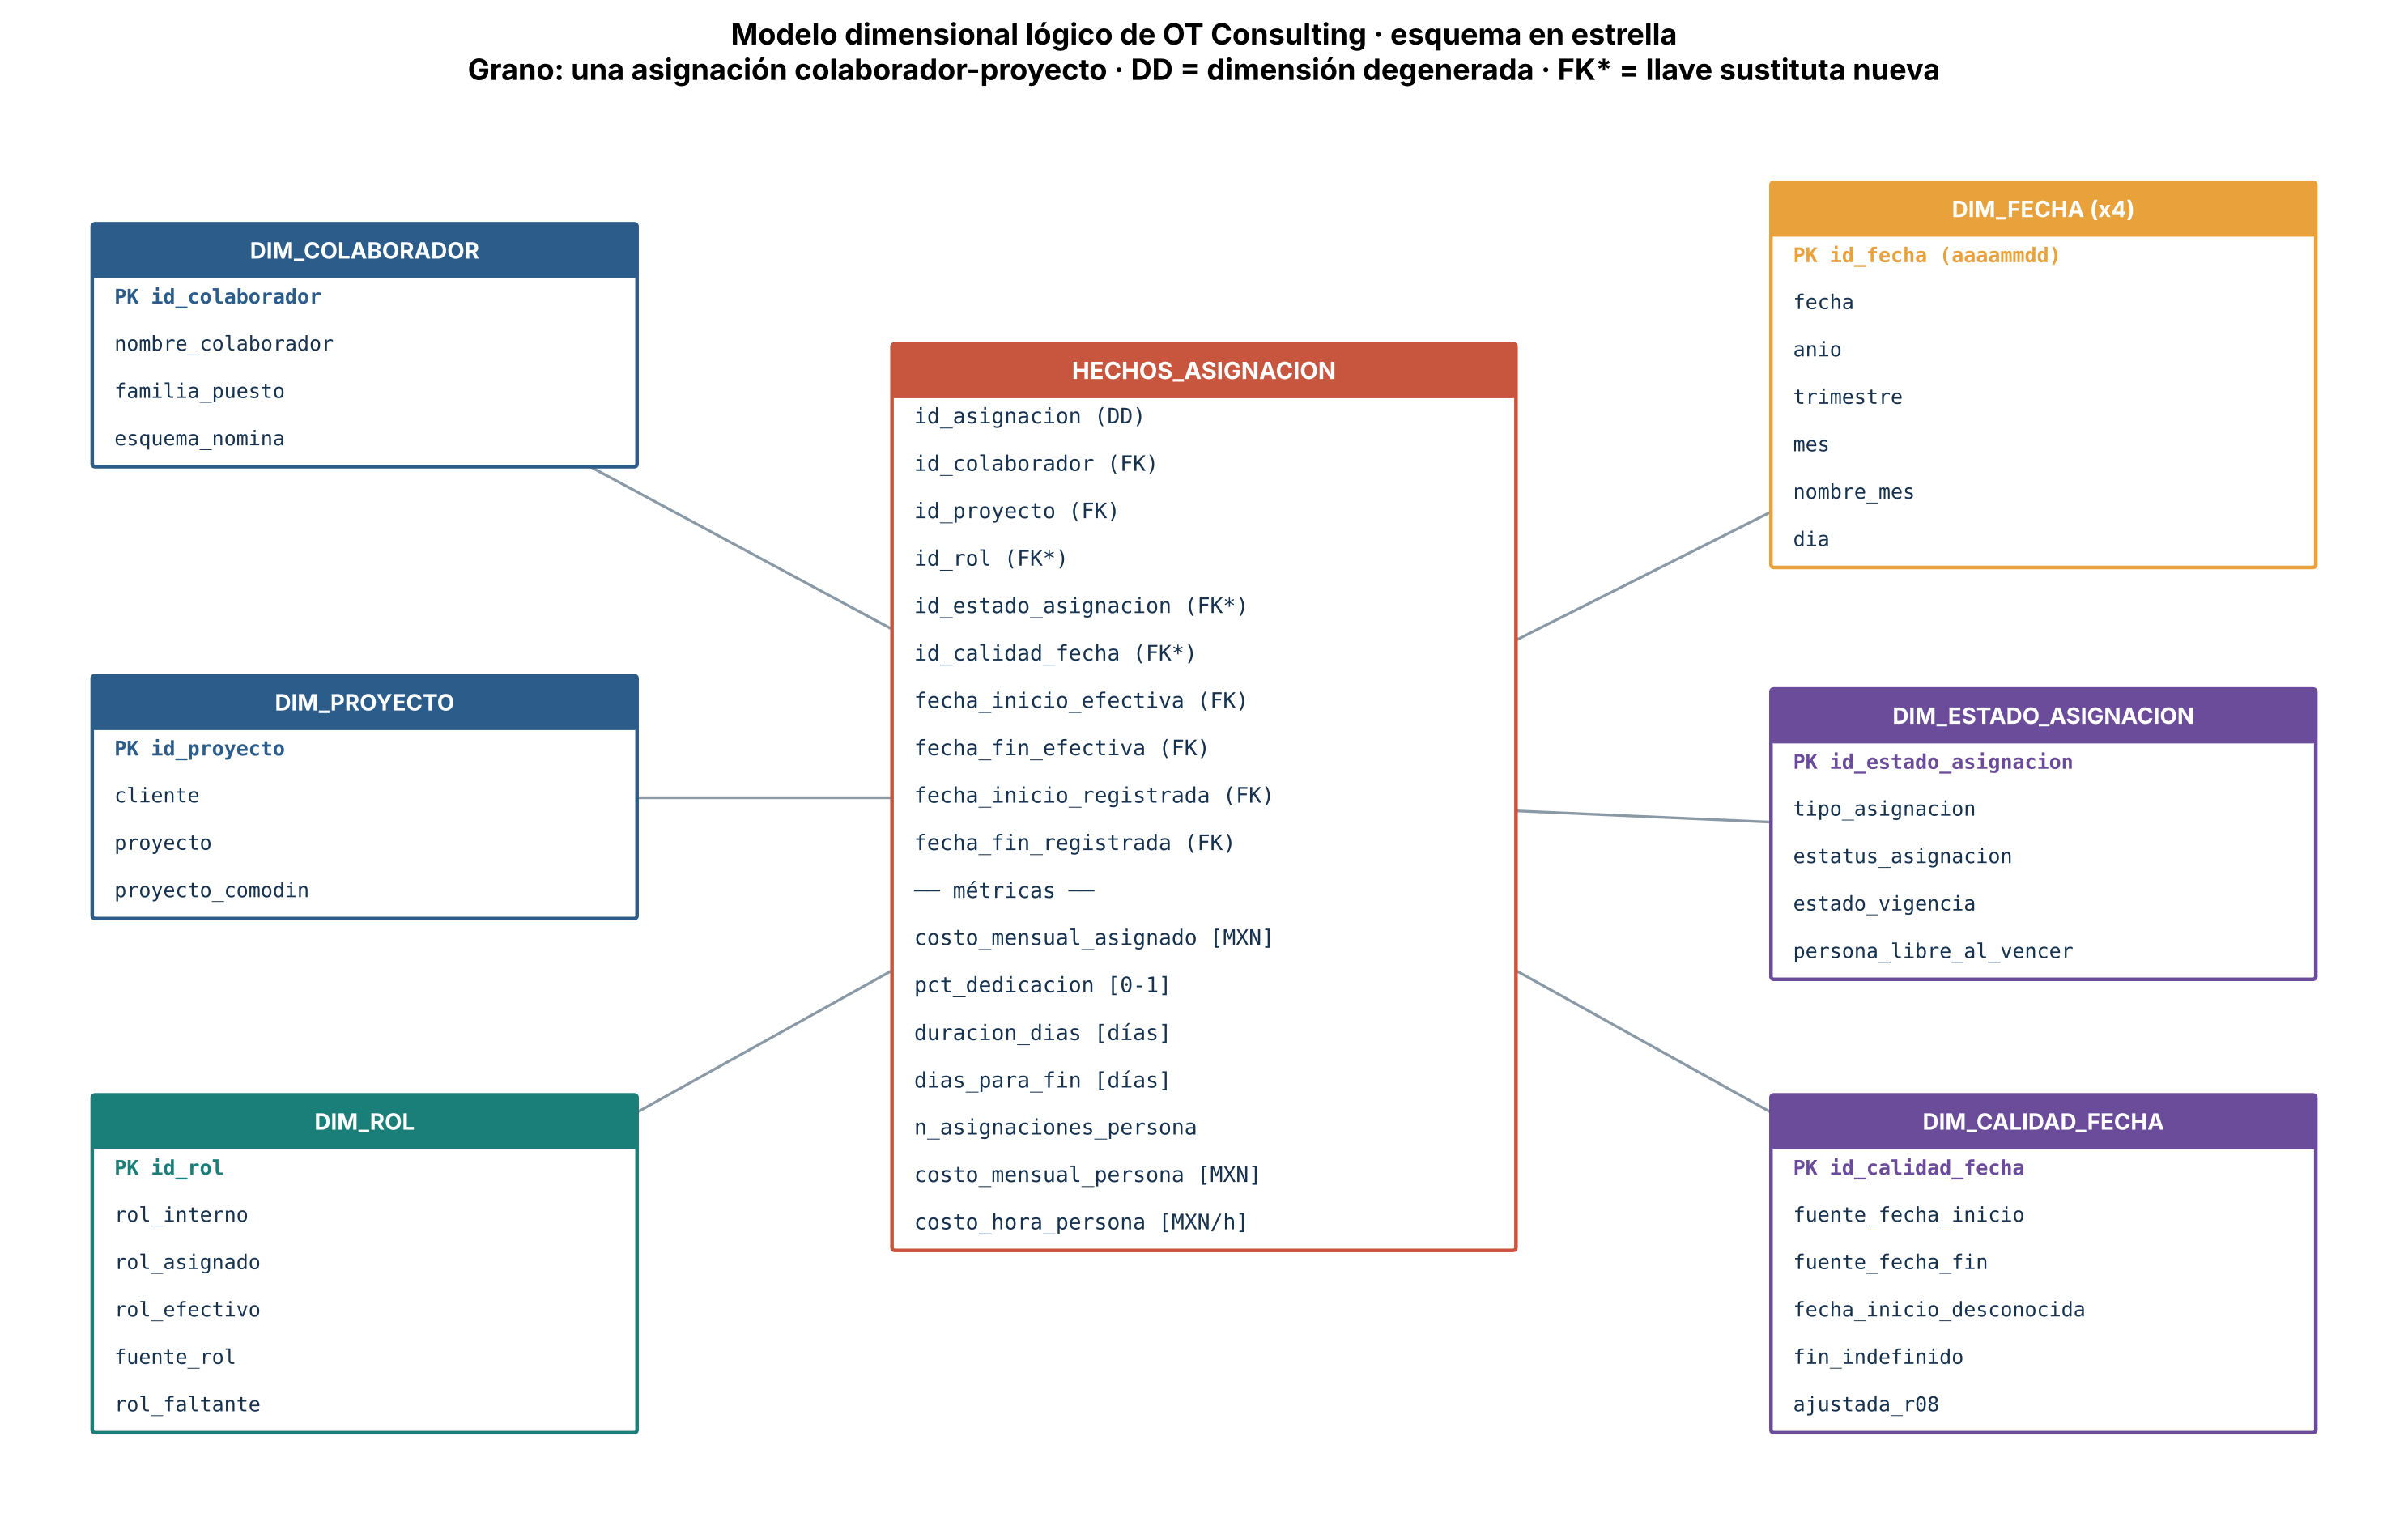

In [8]:
# Diagrama del modelo en estrella
def caja(ax, x, y, titulo, filas, color, w=3.2, fs=9):
    h = 0.32 * (len(filas) + 1)
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle='round,pad=0.02', fc='white', ec=color, lw=1.6))
    ax.add_patch(FancyBboxPatch((x - w/2, y + h/2 - 0.32), w, 0.32, boxstyle='round,pad=0.02', fc=color, ec=color))
    ax.text(x, y + h/2 - 0.16, titulo, ha='center', va='center', color='white', fontweight='bold', fontsize=fs + 1)
    for k, f in enumerate(filas):
        ax.text(x - w/2 + 0.12, y + h/2 - 0.32 * (k + 1.5), f, va='center', fontsize=fs, family='monospace',
                color=TINTA if not f.startswith('PK') else color, fontweight='bold' if f.startswith('PK') else 'normal')
    return h

fig, ax = plt.subplots(figsize=(15, 9.5))
ax.set_xlim(0, 15); ax.set_ylim(0, 9.5); ax.axis('off')
hechos = ['id_asignacion (DD)', 'id_colaborador (FK)', 'id_proyecto (FK)', 'id_rol (FK*)',
          'id_estado_asignacion (FK*)', 'id_calidad_fecha (FK*)', 'fecha_inicio_efectiva (FK)',
          'fecha_fin_efectiva (FK)', 'fecha_inicio_registrada (FK)', 'fecha_fin_registrada (FK)',
          '── métricas ──', 'costo_mensual_asignado [MXN]', 'pct_dedicacion [0-1]', 'duracion_dias [días]',
          'dias_para_fin [días]', 'n_asignaciones_persona', 'costo_mensual_persona [MXN]', 'costo_hora_persona [MXN/h]']
dims = {
    'DIM_COLABORADOR': ((2.2, 7.8), ['PK id_colaborador', 'nombre_colaborador', 'familia_puesto', 'esquema_nomina'], '#2B5C8A'),
    'DIM_PROYECTO':    ((2.2, 4.75), ['PK id_proyecto', 'cliente', 'proyecto', 'proyecto_comodin'], '#2B5C8A'),
    'DIM_ROL':         ((2.2, 1.6), ['PK id_rol', 'rol_interno', 'rol_asignado', 'rol_efectivo', 'fuente_rol', 'rol_faltante'], VERDE),
    'DIM_FECHA (x4)':  ((12.8, 7.6), ['PK id_fecha (aaaammdd)', 'fecha', 'anio', 'trimestre', 'mes', 'nombre_mes', 'dia'], AMBAR),
    'DIM_ESTADO_ASIGNACION': ((12.8, 4.5), ['PK id_estado_asignacion', 'tipo_asignacion', 'estatus_asignacion', 'estado_vigencia', 'persona_libre_al_vencer'], '#6B4C9A'),
    'DIM_CALIDAD_FECHA': ((12.8, 1.6), ['PK id_calidad_fecha', 'fuente_fecha_inicio', 'fuente_fecha_fin', 'fecha_inicio_desconocida', 'fin_indefinido', 'ajustada_r08'], '#6B4C9A'),
}
for nombre, ((x, y), filas, c) in dims.items():
    ax.plot([x, 7.5], [y, 4.75], color=GRIS, lw=1.2, zorder=0)
    caja(ax, x, y, nombre, filas, c, w=3.4)
caja(ax, 7.5, 4.75, 'HECHOS_ASIGNACION', hechos, ROJO, w=3.9, fs=9.5)
ax.set_title('Modelo dimensional lógico de OT Consulting · esquema en estrella\n'
             'Grano: una asignación colaborador-proyecto · DD = dimensión degenerada · FK* = llave sustituta nueva',
             fontsize=13)
plt.tight_layout(); plt.show()

### 7.1 Prueba del modelo
Para comprobar que el modelo lógico **sí se puede implementar**, la siguiente celda construye la estrella en pandas a partir de `asignaciones_acondicionada` y revisa tres cosas:
- la integridad referencial: ninguna llave foránea queda huérfana,
- que la métrica aditiva cuadre con la Etapa 3,
- y que el modelo responda una pregunta de negocio.

In [9]:
def dim_sustituta(df, columnas, llave):
    d = df[columnas].drop_duplicates().reset_index(drop=True)
    d.insert(0, llave, np.arange(1, len(d) + 1))
    return d

DIM_ROL = dim_sustituta(asig, ['rol_interno', 'rol_asignado', 'rol_efectivo', 'fuente_rol', 'rol_faltante'], 'id_rol')
DIM_ESTADO = dim_sustituta(asig, ['tipo_asignacion', 'estatus_asignacion', 'estado_vigencia', 'persona_libre_al_vencer'], 'id_estado_asignacion')
DIM_CALIDAD = dim_sustituta(asig, ['fuente_fecha_inicio', 'fuente_fecha_fin', 'fecha_inicio_desconocida', 'fin_indefinido', 'ajustada_r08'], 'id_calidad_fecha')
DIM_PROYECTO = proy[['id_proyecto', 'cliente', 'proyecto', 'proyecto_comodin']]
DIM_COLABORADOR = col[['id_colaborador', 'nombre_completo', 'familia_puesto', 'esquema_nomina']].rename(columns={'nombre_completo': 'nombre_colaborador'})

COLS_FECHA = ['fecha_inicio_efectiva', 'fecha_fin_efectiva', 'fecha_inicio_registrada', 'fecha_fin_registrada']
fechas = pd.to_datetime(asig[COLS_FECHA].stack())
cal = pd.DataFrame({'fecha': pd.date_range(fechas.min(), fechas.max(), freq='D')})
cal['id_fecha'] = cal.fecha.dt.strftime('%Y%m%d').astype(int)
cal = cal.assign(anio=cal.fecha.dt.year, trimestre=cal.fecha.dt.quarter, mes=cal.fecha.dt.month,
                 nombre_mes=cal.fecha.dt.month_name(), dia=cal.fecha.dt.day)
DESCONOCIDA = pd.DataFrame([{'id_fecha': 0, 'fecha': pd.NaT, 'anio': None, 'trimestre': None, 'mes': None, 'nombre_mes': 'DESCONOCIDA', 'dia': None}])
DIM_FECHA = pd.concat([DESCONOCIDA, cal[DESCONOCIDA.columns]], ignore_index=True)

h = (asig.merge(DIM_ROL).merge(DIM_ESTADO).merge(DIM_CALIDAD))
for c in COLS_FECHA:   # rol múltiple de la fecha: nulo -> miembro desconocido (0)
    h[c] = pd.to_datetime(h[c]).dt.strftime('%Y%m%d').fillna('0').astype(int)
METRICAS = ['costo_mensual_asignado', 'pct_dedicacion', 'duracion_dias', 'dias_para_fin',
            'n_asignaciones_persona', 'costo_mensual_persona', 'costo_hora_persona']
HECHOS_ASIGNACION = h[['id_asignacion', 'id_colaborador', 'id_proyecto', 'id_rol', 'id_estado_asignacion',
                       'id_calidad_fecha'] + COLS_FECHA + METRICAS]

# Validaciones del modelo
fk = {'id_colaborador': DIM_COLABORADOR, 'id_proyecto': DIM_PROYECTO, 'id_rol': DIM_ROL,
      'id_estado_asignacion': DIM_ESTADO, 'id_calidad_fecha': DIM_CALIDAD}
huerfanas = {k: int((~HECHOS_ASIGNACION[k].isin(d[k])).sum()) for k, d in fk.items()}
huerfanas.update({c: int((~HECHOS_ASIGNACION[c].isin(DIM_FECHA.id_fecha)).sum()) for c in COLS_FECHA})
print('Filas en HECHOS_ASIGNACION:', len(HECHOS_ASIGNACION), '| mismas que la tabla acondicionada:', len(HECHOS_ASIGNACION) == len(asig))
print('Llaves foráneas huérfanas:', sum(huerfanas.values()), huerfanas)
print(f"Suma de costo_mensual_asignado: ${HECHOS_ASIGNACION.costo_mensual_asignado.sum():,.0f}  (Etapa 3: $1,924,711)")
print('Dedicación máxima por persona:', HECHOS_ASIGNACION.groupby('id_colaborador').pct_dedicacion.sum().max(), '(R04: <= 1)')
pd.DataFrame({'tabla': ['HECHOS_ASIGNACION', 'DIM_COLABORADOR', 'DIM_PROYECTO', 'DIM_ROL', 'DIM_FECHA',
                        'DIM_ESTADO_ASIGNACION', 'DIM_CALIDAD_FECHA'],
              'filas': [len(x) for x in [HECHOS_ASIGNACION, DIM_COLABORADOR, DIM_PROYECTO, DIM_ROL, DIM_FECHA, DIM_ESTADO, DIM_CALIDAD]]})

Filas en HECHOS_ASIGNACION: 31 | mismas que la tabla acondicionada: True
Llaves foráneas huérfanas: 0 {'id_colaborador': 0, 'id_proyecto': 0, 'id_rol': 0, 'id_estado_asignacion': 0, 'id_calidad_fecha': 0, 'fecha_inicio_efectiva': 0, 'fecha_fin_efectiva': 0, 'fecha_inicio_registrada': 0, 'fecha_fin_registrada': 0}
Suma de costo_mensual_asignado: $1,924,711  (Etapa 3: $1,924,711)
Dedicación máxima por persona: 1.0 (R04: <= 1)


,tabla,filas
0,HECHOS_ASIGNACION,31
1,DIM_COLABORADOR,107
2,DIM_PROYECTO,12
3,DIM_ROL,12
4,DIM_FECHA,1094
5,DIM_ESTADO_ASIGNACION,5
6,DIM_CALIDAD_FECHA,5


In [10]:
# El modelo ya responde preguntas de negocio: P5 (costo por cliente) y P2 (vigencia) desde la estrella
p5 = (HECHOS_ASIGNACION.merge(DIM_PROYECTO, on='id_proyecto')
        .groupby('cliente').agg(asignaciones=('id_asignacion', 'count'),
                                costo_mensual=('costo_mensual_asignado', 'sum'),
                                costo_hora_promedio=('costo_hora_persona', 'mean'))
        .sort_values('costo_mensual', ascending=False).round(0))
p2 = (HECHOS_ASIGNACION.merge(DIM_ESTADO, on='id_estado_asignacion')
        .groupby('estado_vigencia').agg(asignaciones=('id_asignacion', 'count'),
                                        costo_mensual=('costo_mensual_asignado', 'sum')).round(0))
display(p5)
p2

,asignaciones,costo_mensual,costo_hora_promedio
cliente,,,
METALSA,23,1587399.0,445.0
GRUPO DALTILE,3,172382.0,464.0
ALLEGION,5,164929.0,206.0


,asignaciones,costo_mensual
estado_vigencia,,
INDEFINIDA / SIN FECHA FIN,23,1587399.0
MÁS DE 90 DÍAS,5,164929.0
VENCIDA,3,172382.0


<a id="8"></a>
## 8. Hallazgos, patrones y recomendaciones para OT Consulting

Con los datos limpios y el modelo listo, el análisis deja ver **cinco patrones** que afectan el negocio de OTC. Las dos gráficas siguientes muestran los dos que tienen comportamiento en el tiempo o entre categorías.

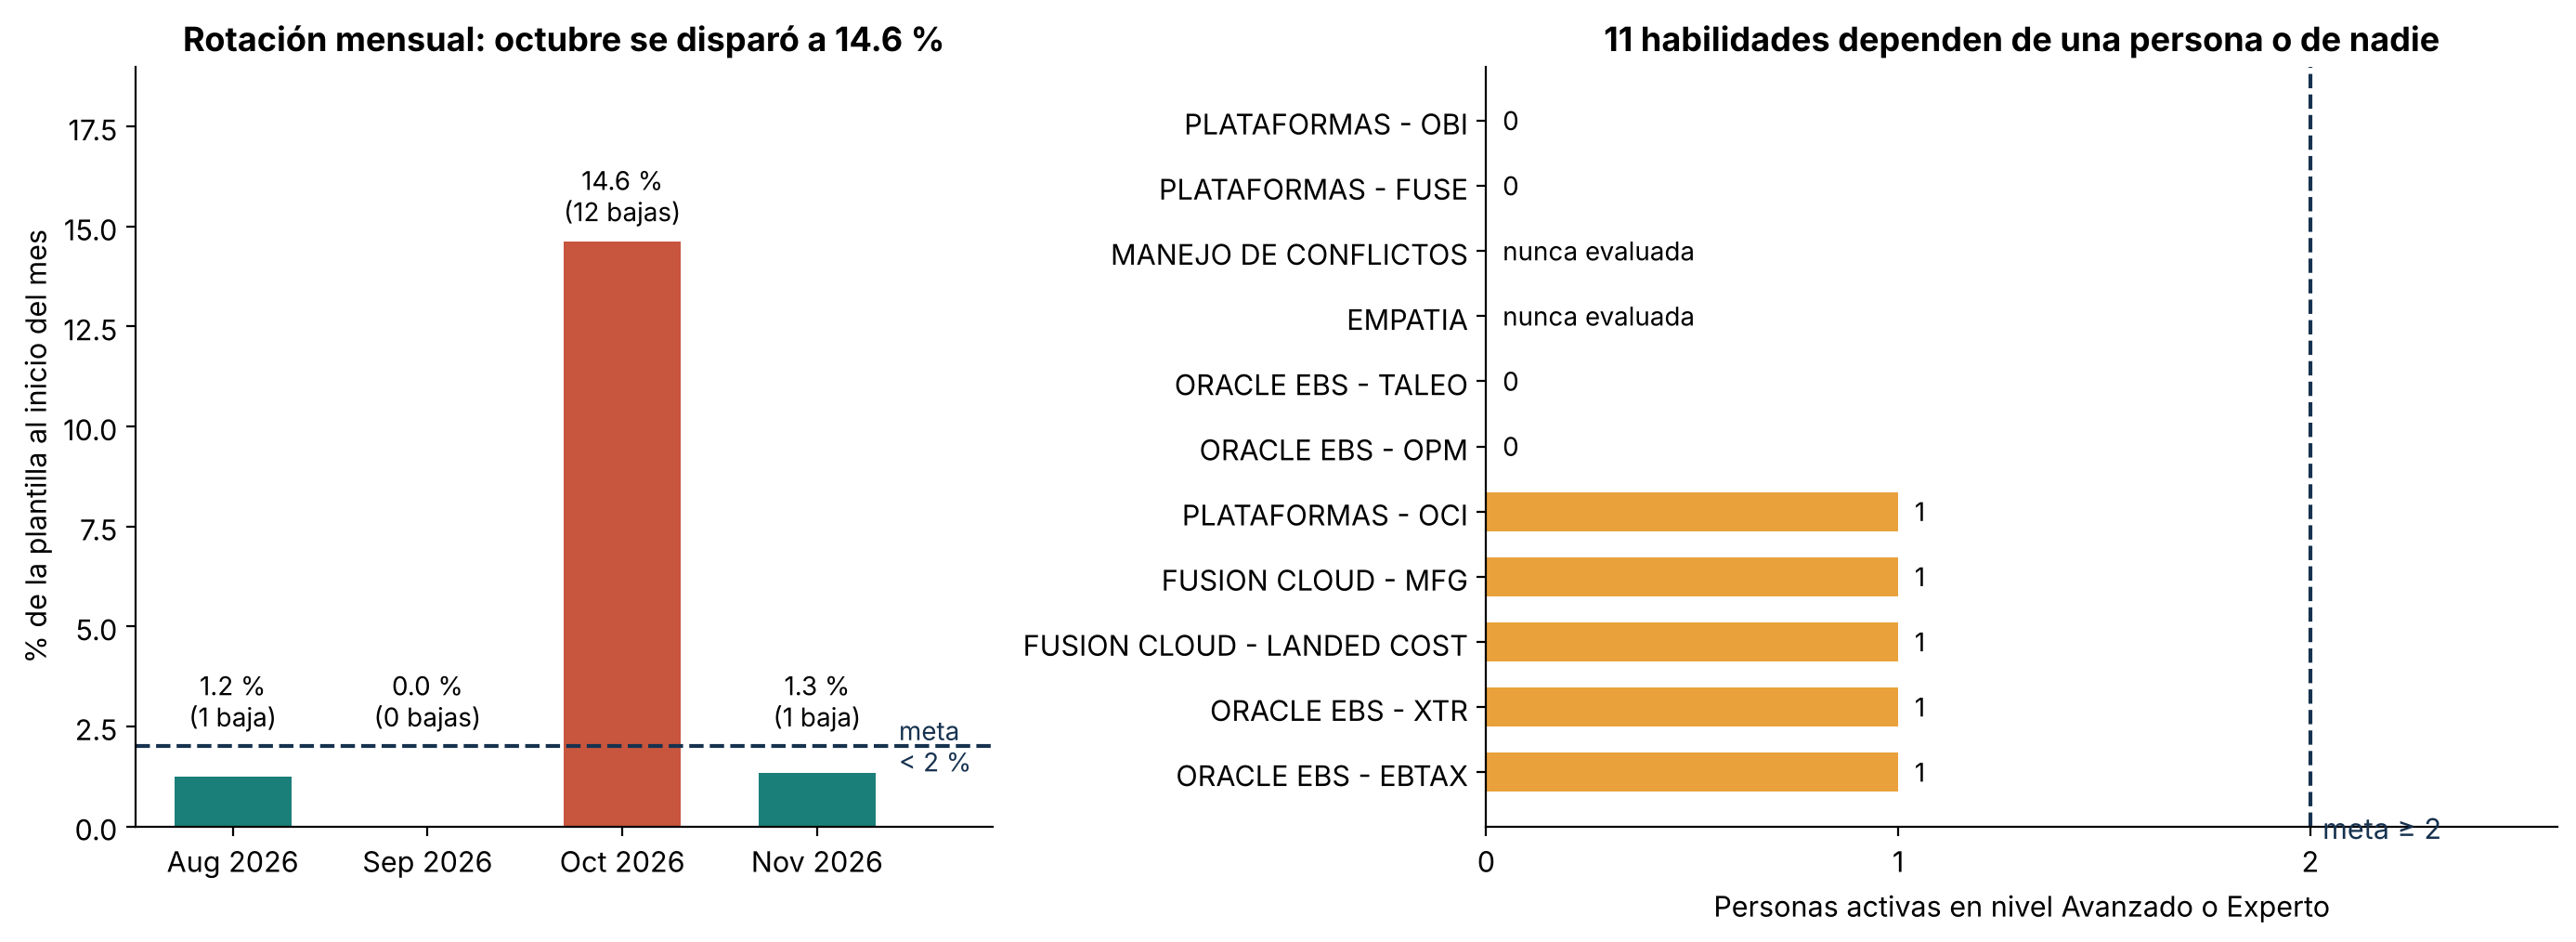

Bajas sin fecha (no entran en la gráfica): 18


In [11]:
# Patrón 1: rotación por mes. Patrón 2: habilidades que dependen de una o ninguna persona
meses = pd.period_range('2026-08', '2026-11', freq='M')
rot = []
for m in meses:
    ini = m.start_time
    hc = ((col.fecha_incorporacion < ini) & (col.fecha_baja.isna() | (col.fecha_baja >= ini))
          & ~(col.estatus_corte.eq('BAJA') & col.fecha_baja.isna())).sum()
    bajas = ((col.anio_mes_baja == str(m)) & col.estatus_corte.eq('BAJA')).sum()
    rot.append((m.strftime('%b %Y'), bajas, bajas / hc * 100))
rot = pd.DataFrame(rot, columns=['mes', 'bajas', 'rotacion_pct'])

baja = cob[cob.cobertura_baja].sort_values(['n_nivel3plus_activos', 'habilidad'], ascending=[False, True])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})
cols = [ROJO if v > 2 else VERDE for v in rot.rotacion_pct]
a1.bar(rot.mes, rot.rotacion_pct, color=cols, width=0.6)
a1.axhline(2, color=TINTA, ls='--', lw=1.5)
a1.text(3.42, 2, 'meta\n< 2 %', va='center', ha='left', color=TINTA, fontsize=10)
for i, r in rot.iterrows():
    a1.text(i, max(r.rotacion_pct, 2) + 0.5, f'{r.rotacion_pct:.1f} %\n({r.bajas} baja' + ('' if r.bajas == 1 else 's') + ')', ha='center', fontsize=10)
a1.set_xlim(-0.5, 3.9); a1.set_ylim(0, 19); a1.set_ylabel('% de la plantilla al inicio del mes')
a1.set_title('Rotación mensual: octubre se disparó a 14.6 %')

etq = [h.replace('PLATAFORMAS TECNOLÓGICAS', 'PLATAFORMAS').replace('ORACLE FUSION CLOUD', 'FUSION CLOUD').replace('OTROS - ', '') for h in baja.habilidad]
c2 = [AMBAR if n == 1 else ROJO for n in baja.n_nivel3plus_activos]
a2.barh(etq, baja.n_nivel3plus_activos, color=c2, height=0.6)
a2.axvline(2, color=TINTA, ls='--', lw=1.5); a2.text(2.03, -0.6, 'meta ≥ 2', color=TINTA, va='top')
for i, (n, sin) in enumerate(zip(baja.n_nivel3plus_activos, baja.sin_evaluaciones)):
    a2.text(n + 0.04, i, 'nunca evaluada' if sin else f'{n}', va='center', fontsize=10)
a2.set_xlim(0, 2.6); a2.set_xticks([0, 1, 2]); a2.set_xlabel('Personas activas en nivel Avanzado o Experto')
a2.set_title('11 habilidades dependen de una persona o de nadie')
plt.tight_layout(); plt.show()
print(f"Bajas sin fecha (no entran en la gráfica): {col.baja_sin_fecha.sum()}")

**Los cinco patrones:**
1. **La capacidad ociosa no está donde falta gente.** 45 activos no tienen asignación, y 21 de ellos son consultores ($1.09 M al mes). Al mismo tiempo, 4 proyectos en curso no tienen a nadie: AMS Manufactura (Metalsa), Soporte Oracle Cloud (Citi), Soporte DBA (Fanosa) y Shine (Rent a Center). O hay un desajuste entre oferta y demanda, o la captura está incompleta; las dos cosas son decisiones de Dirección.
2. **La rotación se concentra en un mes.** Octubre tuvo 12 bajas, 7 veces la meta. Las bajas que tienen puesto registrado son de **consultores senior**, el perfil más caro de reponer.
3. **El conocimiento crítico depende de pocas personas.** 6 habilidades no tienen a nadie en nivel Avanzado o Experto (por ejemplo OPM, TALEO, OBI y FUSE) y 5 tienen a una sola persona.
4. **El negocio depende de un cliente.** Metalsa concentra el **82 %** del costo asignado ($1.59 M de $1.92 M). Si ese cliente se va, la banca casi se duplica.
5. **La captura es el cuello de botella.** 29 de 31 asignaciones no tienen rol y 21 no tienen fecha de inicio. Sin esa información, ningún indicador es confiable.

### Recomendaciones priorizadas
La siguiente tabla ordena las recomendaciones por prioridad. Cada una ataca uno de los patrones, se apoya en una cifra del análisis y tiene un responsable y un plazo sugeridos para validar con OTC.

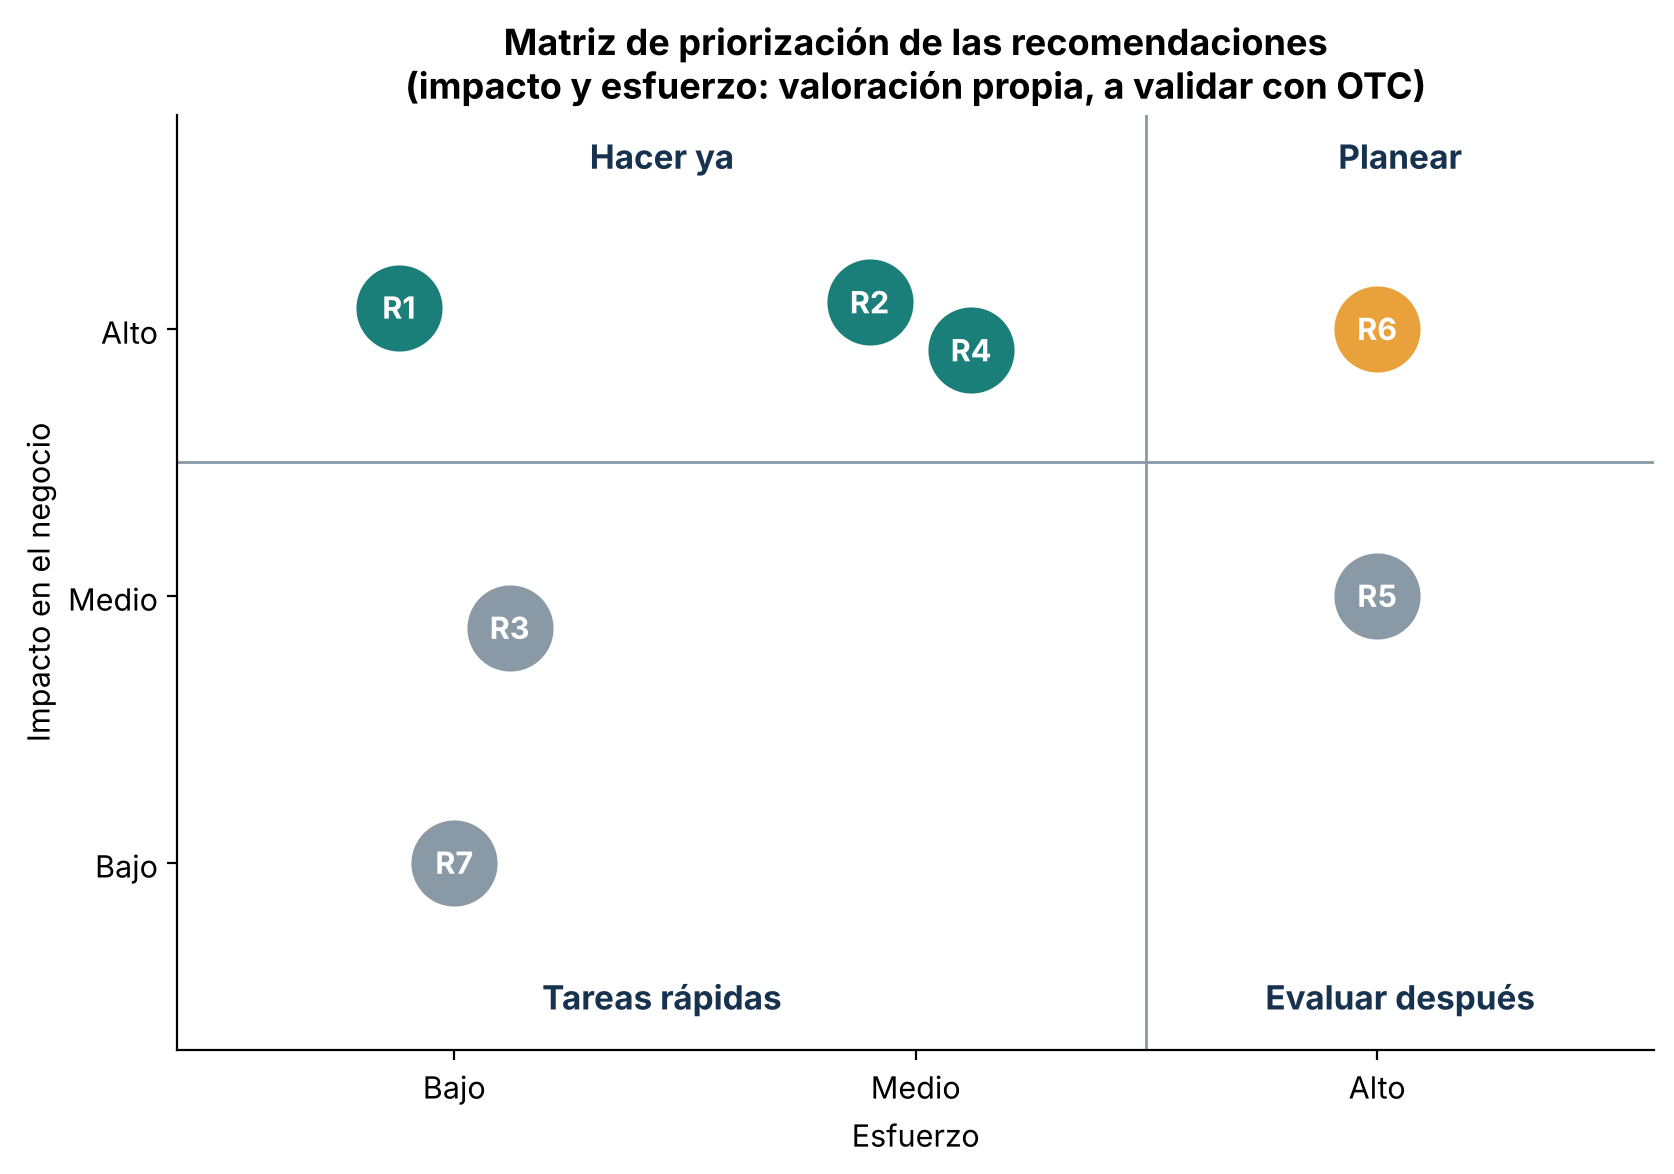

,id,recomendación,evidencia,valor para OTC,responsable,plazo
0,R1,"Completar la captura de asignaciones: rol, fechas y % de dedicación",45 activos sin asignación; 29 de 31 sin rol; 21 sin inicio,"Hace confiables la utilización y la banca, que deciden $1.99 M al mes",PMO / Operaciones,2 semanas
1,R2,Asignar la banca consultiva a los 4 proyectos en curso sin personal,21 consultores en banca ($1.09 M/mes); 13 con matriz confiable,"Cada consultor reasignado convierte ~$51,700/mes de costo ocioso en costo de proyecto",Dirección de Operaciones,1 mes
2,R3,Decidir la extensión o el cierre de Marazzi y de los proyectos vencidos,"3 asignaciones vencidas el 23-sep ($172,382/mes); 2 proyectos en curso vencidos",Evita costo sin contrato o libera a 2 personas para otros proyectos,Dirección Comercial,Inmediato
3,R4,Registrar el motivo de baja y lanzar un plan de retención para consultores senior,Rotación de octubre de 14.6 % contra una meta < 2 %,Reduce el costo de reemplazo y la pérdida de conocimiento del cliente,Recursos Humanos,1–2 meses
4,R5,Capacitar o certificar en las habilidades críticas,6 habilidades sin nadie Avanzado+ y 5 con una sola persona,Quita la dependencia de una persona y amplía la oferta de servicios,Capital Humano,3 meses
5,R6,Diversificar la cartera usando la banca para crecer en otros clientes,Metalsa concentra el 82 % del costo asignado,Baja el riesgo de que un solo cliente duplique la banca,Dirección General / Comercial,6 meses
6,R7,Recuperar equipos de bajas y completar expedientes,"9 equipos por recuperar ($40,693 conocidos); 34 expedientes incompletos; 61 contratos pendientes",Reduce el riesgo patrimonial y legal,Administración / RH,1 mes


In [12]:
recs = pd.DataFrame([
 ('R1', 'Completar la captura de asignaciones: rol, fechas y % de dedicación', '45 activos sin asignación; 29 de 31 sin rol; 21 sin inicio',
  'Hace confiables la utilización y la banca, que deciden $1.99 M al mes', 'PMO / Operaciones', '2 semanas', 3, 1),
 ('R2', 'Asignar la banca consultiva a los 4 proyectos en curso sin personal', '21 consultores en banca ($1.09 M/mes); 13 con matriz confiable',
  'Cada consultor reasignado convierte ~$51,700/mes de costo ocioso en costo de proyecto', 'Dirección de Operaciones', '1 mes', 3, 2),
 ('R3', 'Decidir la extensión o el cierre de Marazzi y de los proyectos vencidos', '3 asignaciones vencidas el 23-sep ($172,382/mes); 2 proyectos en curso vencidos',
  'Evita costo sin contrato o libera a 2 personas para otros proyectos', 'Dirección Comercial', 'Inmediato', 2, 1),
 ('R4', 'Registrar el motivo de baja y lanzar un plan de retención para consultores senior', 'Rotación de octubre de 14.6 % contra una meta < 2 %',
  'Reduce el costo de reemplazo y la pérdida de conocimiento del cliente', 'Recursos Humanos', '1–2 meses', 3, 2),
 ('R5', 'Capacitar o certificar en las habilidades críticas', '6 habilidades sin nadie Avanzado+ y 5 con una sola persona',
  'Quita la dependencia de una persona y amplía la oferta de servicios', 'Capital Humano', '3 meses', 2, 3),
 ('R6', 'Diversificar la cartera usando la banca para crecer en otros clientes', 'Metalsa concentra el 82 % del costo asignado',
  'Baja el riesgo de que un solo cliente duplique la banca', 'Dirección General / Comercial', '6 meses', 3, 3),
 ('R7', 'Recuperar equipos de bajas y completar expedientes', '9 equipos por recuperar ($40,693 conocidos); 34 expedientes incompletos; 61 contratos pendientes',
  'Reduce el riesgo patrimonial y legal', 'Administración / RH', '1 mes', 1, 1),
], columns=['id', 'recomendación', 'evidencia', 'valor para OTC', 'responsable', 'plazo', 'impacto', 'esfuerzo'])

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.axhline(2.5, color=GRIS, lw=1); ax.axvline(2.5, color=GRIS, lw=1)
desv = {'R1': (-0.12, 0.08), 'R3': (0.12, -0.12), 'R7': (0, 0), 'R2': (-0.1, 0.1), 'R4': (0.12, -0.08), 'R5': (0, 0), 'R6': (0, 0)}
for _, r in recs.iterrows():
    dx, dy = desv[r.id]
    x, y = r.esfuerzo + dx, r.impacto + dy
    ax.scatter(x, y, s=900, color=VERDE if (r.impacto >= 2.5 and r.esfuerzo <= 2) else (AMBAR if r.impacto >= 2.5 else GRIS), zorder=3)
    ax.text(x, y, r.id, ha='center', va='center', color='white', fontweight='bold', zorder=4)
for (x, y, t) in [(1.45, 3.6, 'Hacer ya'), (3.05, 3.6, 'Planear'), (1.45, 0.45, 'Tareas rápidas'), (3.05, 0.45, 'Evaluar después')]:
    ax.text(x, y, t, ha='center', fontsize=12, fontweight='bold', color=TINTA)
ax.set_xlim(0.4, 3.6); ax.set_ylim(0.3, 3.8)
ax.set_xticks([1, 2, 3], ['Bajo', 'Medio', 'Alto']); ax.set_yticks([1, 2, 3], ['Bajo', 'Medio', 'Alto'])
ax.set_xlabel('Esfuerzo'); ax.set_ylabel('Impacto en el negocio')
ax.set_title('Matriz de priorización de las recomendaciones\n(impacto y esfuerzo: valoración propia, a validar con OTC)')
plt.tight_layout(); plt.show()
with pd.option_context('display.max_colwidth', None):
    display(recs.drop(columns=['impacto', 'esfuerzo']))

<a id="9"></a>
## 9. Conclusiones y acciones futuras

### Conclusiones de las 4 etapas
1. **El problema principal de OTC es la calidad y la captura de los datos, no la falta de datos.** 21 de los 60 hallazgos son de severidad alta y casi todos están en el hecho central, la asignación.
2. **Con los datos actuales, la banca cuesta más que lo asignado a proyectos:** $1.99 M contra $1.92 M al mes, es decir, 50.9 % de la nómina activa contra una meta de 10 %. Hay que leer esta cifra con cuidado: parte de los 45 activos "sin asignación" puede ser falta de captura. Confirmarlo con OTC es la primera acción de negocio.
3. **El tratamiento cambió conclusiones.** Con R08, Marazzi pasó de "por vencer" a "vencida". Sin reglas de negocio, el tablero habría mostrado una realidad falsa.
4. **El modelo en estrella está listo y probado:** 31 asignaciones, 6 dimensiones, 0 llaves huérfanas y la métrica aditiva cuadra con la Etapa 3.

### Acciones futuras del reto
- **Modelo físico y carga:** convertir el modelo lógico en tablas (DDL) en SQL Server o PostgreSQL y cargar las tablas acondicionadas.
- **Automatización del ETL:** hacer que la fecha de corte y las rutas sean parámetros, y programar la ejecución mensual, por ejemplo con GitHub Actions. Si falla una validación crítica, la carga se detiene.
- **Tablero de BI** (Power BI) con los 9 indicadores y su semáforo contra la meta, para el usuario principal.
- **Validar con OTC** las metas sugeridas, el caso de la banca y la validación V06 (los PM que no aparecen en el catálogo).
- **Ampliar el modelo** con más tablas de hechos: una foto mensual de la plantilla (rotación y banca histórica), habilidades y equipos. También agregar historial (SCD tipo 2) para puesto y esquema de nómina.
- **Pedir los datos que faltan:** % de dedicación real o timesheets, tarifa e ingreso por proyecto (para medir margen), perfil requerido por proyecto (para completar P8) y motivo de baja.

---
*Fuente: tablas acondicionadas de la Etapa 3 (corte 17-nov-2026). Las cifras de esta presentación se calculan en este cuaderno.*